<h3 style="color:white">EV Charging Demand Regression</h3>

In [4]:
import pandas as pd

df = pd.read_csv("../data/processed/ChargingRecords_cleaned.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (72826, 13)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81


<h3 style="color:white">Feature and Target Selection</h3>

In [5]:
# Select input features
X = df[[
    "UserID",
    "ChargerID",
    "ChargerCompany",
    "Location",
    "ChargerType",
    "Duration"
]]

# Select target
y = df["Demand"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

X.head()

Features Shape: (72826, 6)
Target Shape: (72826,)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,Duration
0,0,1,1,hotel,0,185
1,0,1,1,hotel,0,90
2,0,1,1,hotel,0,60
3,0,1,1,hotel,0,344
4,0,1,1,hotel,0,300


<h3 style="color:white">Encoding Categorical Features</h3>

In [6]:
X = pd.get_dummies(X, columns=["Location"], dtype=int)

print("Features Shape after Encoding:", X.shape)
X.head()

Features Shape after Encoding: (72826, 19)


,UserID,ChargerID,ChargerCompany,ChargerType,Duration,Location_accommodation,Location_apartment,Location_bus garage,Location_camping,Location_company,Location_golf,Location_hotel,Location_market,Location_public area,Location_public institution,Location_public parking lot,Location_resort,Location_restaurant,Location_sightseeing
0,0,1,1,0,185,0,0,0,0,0,0,1,0,0,0,0,0,0,0
1,0,1,1,0,90,0,0,0,0,0,0,1,0,0,0,0,0,0,0
2,0,1,1,0,60,0,0,0,0,0,0,1,0,0,0,0,0,0,0
3,0,1,1,0,344,0,0,0,0,0,0,1,0,0,0,0,0,0,0
4,0,1,1,0,300,0,0,0,0,0,0,1,0,0,0,0,0,0,0


<h3 style="color:white">Train-Test Split</h3>

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (58260, 19)
Testing Features: (14566, 19)
Training Target: (58260,)
Testing Target: (14566,)


<h3 style="color:white">Linear Regression Model</h3>

In [8]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Linear Regression training completed.")

Linear Regression training completed.


<h3 style="color:white">Linear Regression Evaluation</h3>

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R² Score:", round(r2, 4))

Linear Regression Results
MAE: 6.2987
MSE: 102.5193
RMSE: 10.1252
R² Score: 0.4311


<h3 style="color:white">Decision Tree Regression Model</h3>

In [10]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree training completed.")

Decision Tree training completed.


<h3 style="color:white">Decision Tree Evaluation</h3>

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Results")
print("MAE:", round(dt_mae, 4))
print("MSE:", round(dt_mse, 4))
print("RMSE:", round(dt_rmse, 4))
print("R² Score:", round(dt_r2, 4))

Decision Tree Results
MAE: 2.9266
MSE: 43.0029
RMSE: 6.5577
R² Score: 0.7614


<h3 style="color:white">Random Forest Regression Model</h3>

In [12]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest training completed.")

Random Forest training completed.


<h3 style="color:white">Random Forest Evaluation</h3>

In [13]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", round(rf_mae, 4))
print("MSE:", round(rf_mse, 4))
print("RMSE:", round(rf_rmse, 4))
print("R² Score:", round(rf_r2, 4))

Random Forest Results
MAE: 2.4807
MSE: 25.3661
RMSE: 5.0365
R² Score: 0.8592


<h3 style="color:white">Gradient Boosting Regression Model</h3>

In [14]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


<h3 style="color:white">Gradient Boosting Evaluation</h3>

In [15]:
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting Results")
print("MAE:", round(gb_mae, 4))
print("MSE:", round(gb_mse, 4))
print("RMSE:", round(gb_rmse, 4))
print("R² Score:", round(gb_r2, 4))

Gradient Boosting Results
MAE: 3.6254
MSE: 39.8639
RMSE: 6.3138
R² Score: 0.7788


<h3 style="color:white">Regression Model Comparison</h3>

In [16]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [mae, dt_mae, rf_mae, gb_mae],
    "MSE": [mse, dt_mse, rf_mse, gb_mse],
    "RMSE": [rmse, dt_rmse, rf_rmse, gb_rmse],
    "R2 Score": [r2, dt_r2, rf_r2, gb_r2]
})

results = results.reset_index(drop=True)

results.round(4)

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,6.2987,102.5193,10.1252,0.4311
1,Decision Tree,2.9266,43.0029,6.5577,0.7614
2,Random Forest,2.4807,25.3661,5.0365,0.8592
3,Gradient Boosting,3.6254,39.8639,6.3138,0.7788


In [17]:
[name for name, obj in globals().items()
 if "forest" in name.lower() or "rf" in name.lower()]

['RandomForestRegressor',
 'rf_model',
 'rf_pred',
 'rf_mae',
 'rf_mse',
 'rf_rmse',
 'rf_r2']

In [18]:
import os
import joblib

os.makedirs("../models/regression", exist_ok=True)

joblib.dump(
    rf_model,
    "../models/regression/random_forest_regressor.pkl"
)

print("Random Forest Regressor saved successfully!")

Random Forest Regressor saved successfully!


In [20]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 5.1 MB/s eta 0:00:10
   - -------------------------------------- 2.4/48.9 MB 5.3 MB/s eta 0:00:09
   --- ------------------------------------ 3.9/48.9 MB 5.8 MB/s eta 0:00:08
   ---- ----------------------------------- 5.5/48.9 MB 6.3 MB/s eta 0:00:07
   ----- ---------------------------------- 7.1/48.9 MB 6.5 MB/s eta 0:00:07
   ------- -------------------------------- 8.7/48.9 MB 6.8 MB/s eta 0:00:06
   -------- ------------------------------- 10.5/48.9 MB 7.0 MB/s eta 0:00:06
   ---------- ----------------------------- 12.8/48.9 MB 7.5 MB/s eta 0:00:05
   ------------ --------------------------- 14.9/48.9 MB 7.9 MB/s eta 0:00:05
   ------------- -------------------------- 16.5/48.9 MB 7.8 MB/s eta 0:00:05
   --------------- ------------------------ 18.9/48.9 MB 8.2 MB/s eta 0:00:04
   -----

In [21]:
import xgboost
print(xgboost.__version__)

3.4.1


In [22]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_xgb)
mse = mean_squared_error(y_test, y_pred_xgb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_xgb)

print("XGBoost Regression Results")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R² Score:", round(r2, 4))

XGBoost Regression Results
MAE: 2.9484
MSE: 29.2645
RMSE: 5.4097
R² Score: 0.8376


REGRESSION MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,2.4807,25.3661,5.0365,0.8592
1,XGBoost,2.9484,29.2645,5.4097,0.8376
2,Gradient Boosting,3.6254,39.8639,6.3138,0.7788
3,Decision Tree,2.9266,43.0029,6.5577,0.7614
4,Linear Regression,6.2987,102.5193,10.1252,0.4311


Best Model: Random Forest


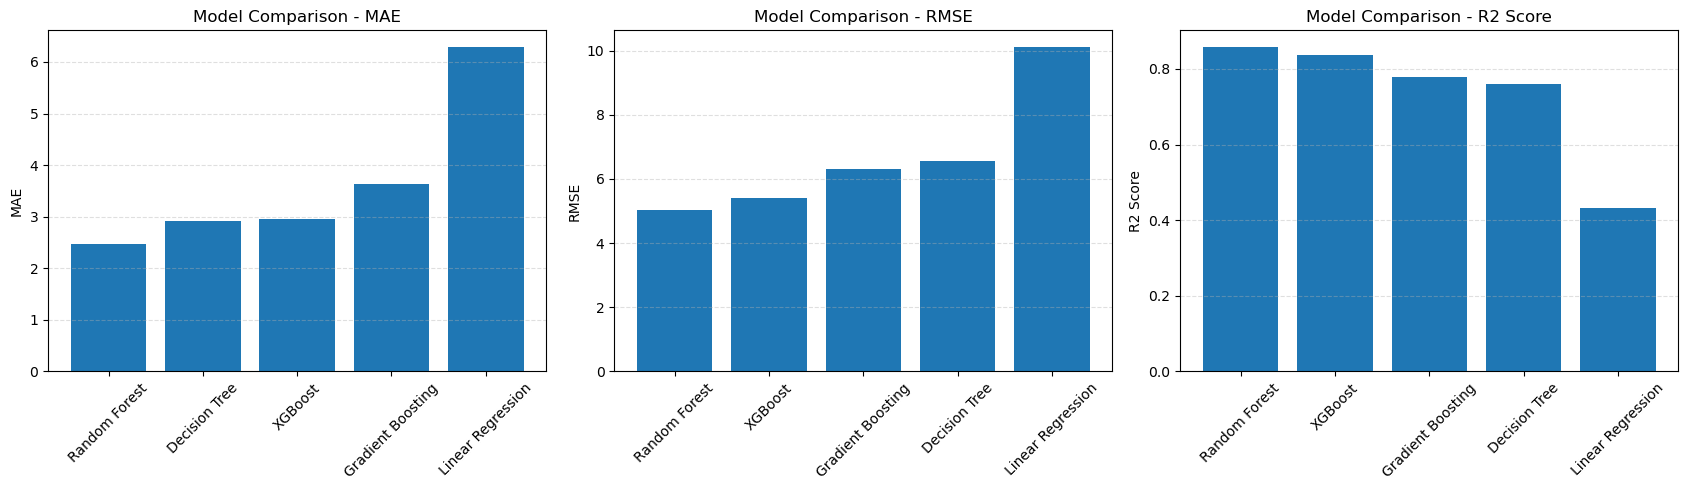

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# Results from your model evaluations
results_df = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": 6.2987,
        "MSE": 102.5193,
        "RMSE": 10.1252,
        "R2 Score": 0.4311
    },
    {
        "Model": "Decision Tree",
        "MAE": 2.9266,
        "MSE": 43.0029,
        "RMSE": 6.5577,
        "R2 Score": 0.7614
    },
    {
        "Model": "Random Forest",
        "MAE": 2.4807,
        "MSE": 25.3661,
        "RMSE": 5.0365,
        "R2 Score": 0.8592
    },
    {
        "Model": "Gradient Boosting",
        "MAE": 3.6254,
        "MSE": 39.8639,
        "RMSE": 6.3138,
        "R2 Score": 0.7788
    },
    {
        "Model": "XGBoost",
        "MAE": 2.9484,
        "MSE": 29.2645,
        "RMSE": 5.4097,
        "R2 Score": 0.8376
    }
])

# Sort by R2 score
results_df = results_df.sort_values(
    by="R2 Score", ascending=False
).reset_index(drop=True)

print("REGRESSION MODEL COMPARISON")
display(results_df)

print("Best Model:", results_df.iloc[0]["Model"])

# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2 Score"]):
    data = results_df.sort_values(
        by=metric,
        ascending=(metric != "R2 Score")
    )

    ax.bar(data["Model"], data[metric])
    ax.set_title(f"Model Comparison - {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()